# 09 · District crop model (real data)

Notebook 08 showed the Kaggle-trained model doesn't transfer: real soil never looks like Kaggle's per-crop N-P-K.
Here we train on real data instead.

- **One row per district:** Soil Health Card N, P, K, pH (`data.district_soil()`, kg/ha, the scale on a farmer's card)
  + NASA POWER 2015-2024 weather at the district's market coordinates.
- **Target:** share of the district's area under each crop (DES, each crop's last 5 reported years): the Kaggle crops
  plus 12 major crops Kaggle lacks (wheat, soybean, groundnut, bajra, jowar, mustard, sesamum, ragi, barley, potato,
  onion, sugarcane; added Nov 4). Crops grown in fewer than 20 districts are dropped. Trained as a multiclass model with one row per district × crop, weighted by the
  area share, so the predicted probability is *the share of farmland that similar places put under each crop*.
- **Validation: leave one state out.** Neighbouring districts share soil, weather and crops, so random folds would
  flatter the model. Every district is scored by a model that never saw its state.
- **Metrics per district:** main crop 1st; main crop in the list; share of list crops the district grows;
  share of the district's area covered by the list. List = top 3 with probability ≥ 5% (as in the app).
- **Baseline:** popularity, the 3 crops with most area in the training states (refit each fold, so it's fair now).

Suitability now means "what farmers in similar soil and climate grow", not "what grows best agronomically":
revealed preference, which bakes in irrigation, markets and habit. The paper must say so.

In [1]:
import sys
sys.path.insert(0, '../project')
import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import data
import recommend

SEED = 42
MIN_DISTRICTS = 20
RESULTS, FIGS = Path('../research/results'), Path('../research/figures')
pd.set_option('display.width', 220)

## 1. Training table

In [2]:
soil = data.district_soil().dropna()
soil = soil[soil.samples >= 100]
area = data.district_yield()[['crop', 'district_code', 'area_ha']]
keep = area.crop.value_counts().loc[lambda s: s >= MIN_DISTRICTS].index
area = area[area.crop.isin(keep)]
d = recommend._tables()[2].merge(soil, on='district_code')
d = d[d.district_code.isin(area.district_code)].reset_index(drop=True)


d = pd.concat([d, pd.DataFrame([recommend.weather(r.lat, r.lon) for r in d.itertuples()])], axis=1)  # same code as the app
shares = area.pivot_table(index='district_code', columns='crop', values='area_ha', fill_value=0).loc[d.district_code]
shares = shares.div(shares.sum(axis=1), axis=0)
classes = list(shares.columns)
S = shares.values
main_idx = S.argmax(axis=1)
states = d.state_name.values
print(f'{len(d)} districts, {d.state_name.nunique()} states, {len(classes)} crops: {", ".join(classes)}')
pd.DataFrame({'main crop in % of districts': pd.Series(np.array(classes)[main_idx]).value_counts(normalize=True) * 100,
              '% of all area': shares.mul(d.set_index('district_code').index.map(area.groupby('district_code').area_ha.sum()), axis=0).sum() / area.area_ha.sum() * 100}).fillna(0).round(1).sort_values('% of all area', ascending=False)

539 districts, 28 states, 27 crops: bajra, banana, barley, blackgram, chickpea, coconut, cotton, groundnut, jowar, jute, lentil, maize, mango, mothbeans, mungbean, mustard, onion, orange, papaya, pigeonpeas, potato, ragi, rice, sesamum, soybean, sugarcane, wheat


,main crop in % of districts,% of all area
rice,50.1,22.3
wheat,21.7,14.0
cotton,5.9,6.1
soybean,4.3,5.9
maize,4.5,4.7
chickpea,0.7,4.2
sugarcane,2.6,2.8
groundnut,2.4,2.5
pigeonpeas,0.4,2.4
jowar,1.9,2.2


## 2. Leave-state-out comparison

In [3]:
FEATURES = {
    'soil + weather (app inputs)': ['N', 'P', 'K', 'ph', 'temperature', 'rainfall'],
    '+ humidity': ['N', 'P', 'K', 'ph', 'temperature', 'humidity', 'rainfall'],
    '+ season weather': ['N', 'P', 'K', 'ph', 'temperature', 'humidity', 'rainfall', 'rain_kharif', 'rain_rabi', 'temp_kharif', 'temp_rabi'],
    'weather only': ['temperature', 'humidity', 'rainfall'],
    'soil only': ['N', 'P', 'K', 'ph'],
}
MODELS = {
    'Random Forest': lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    'LightGBM': lambda: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10,
                                       random_state=SEED, verbose=-1),
    'Logistic regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
}


def long_rows(idx, feats):
    """One row per district x crop with area share > 0, weighted by the share."""
    i, c = np.nonzero(S[idx] > 0)
    return d.loc[idx[i], feats].reset_index(drop=True), c, S[idx][i, c]


def fit(model, X, y, w):
    key = f'{model.steps[-1][0]}__sample_weight' if hasattr(model, 'steps') else 'sample_weight'  # pipelines route by step name
    return model.fit(X, y, **{key: w})


def full_proba(model, X):
    P = np.zeros((len(X), len(classes)))
    P[:, model.classes_] = model.predict_proba(X)  # a fold may miss a rare crop
    return P


def score(P, idx):
    order = np.argsort(-P, axis=1)[:, :3]
    keep = np.take_along_axis(P, order, axis=1) >= recommend.MIN_SUITABILITY
    keep[:, 0] = True
    s, main = S[idx], main_idx[idx]
    picked = [o[k] for o, k in zip(order, keep)]
    return {'main crop 1st %': np.mean(order[:, 0] == main) * 100,
            'main crop in list %': np.mean([m in p for m, p in zip(main, picked)]) * 100,
            'picks grown %': np.mean([np.mean(r[p] > 0) for r, p in zip(s, picked)]) * 100,
            'area covered %': np.mean([r[p].sum() for r, p in zip(s, picked)]) * 100,
            'list length': np.mean([len(p) for p in picked])}


def cv_proba(make, feats, splitter):
    P = np.zeros_like(S)
    for tr, te in splitter.split(d, groups=states):
        X, y, w = long_rows(tr, feats)
        P[te] = full_proba(fit(make(), X, y, w), d.loc[te, feats])
    return P


def popularity_proba(splitter):
    P = np.zeros_like(S)
    for tr, te in splitter.split(d, groups=states):
        P[te] = S[tr].mean(axis=0)
    return P


logo = LeaveOneGroupOut()
all_idx = np.arange(len(d))
rows = {'popularity (training states)': score(popularity_proba(logo), all_idx)}
oof = {}
for mname, make in MODELS.items():
    for fname, feats in FEATURES.items():
        if mname == 'LightGBM' and fname != '+ season weather':
            continue  # weakest on every feature set with 16 crops (commit 0d2b9d9) and the slowest; best set only
        oof[mname, fname] = cv_proba(make, feats, logo)
        rows[f'{mname} · {fname}'] = score(oof[mname, fname], all_idx)
cv = pd.DataFrame(rows).T
cv.round(1)

,main crop 1st %,main crop in list %,picks grown %,area covered %,list length
popularity (training states),50.1,76.3,94.4,61.9,3.0
Random Forest · soil + weather (app inputs),57.1,77.7,90.3,62.3,2.8
Random Forest · + humidity,62.9,81.8,92.2,63.9,2.8
Random Forest · + season weather,62.5,80.5,95.9,65.1,2.7
Random Forest · weather only,57.5,76.6,92.2,61.0,2.8
Random Forest · soil only,46.0,72.9,87.3,57.1,2.8
LightGBM · + season weather,59.9,80.7,99.1,64.3,2.4
Logistic regression · soil + weather (app inputs),49.5,77.7,89.0,61.1,2.9
Logistic regression · + humidity,57.9,80.9,91.0,63.2,2.8
Logistic regression · + season weather,61.4,82.7,96.1,65.7,2.8


In [4]:
# Random 5-fold over districts (not grouped by state): how much would ignoring geography flatter the model?
best_feats = FEATURES['soil + weather (app inputs)']
rand = np.zeros_like(S)
for tr, te in KFold(5, shuffle=True, random_state=SEED).split(d):
    X, y, w = long_rows(tr, best_feats)
    rand[te] = full_proba(fit(MODELS['Random Forest'](), X, y, w), d.loc[te, best_feats])
cv.loc['Random Forest · app inputs, random district folds'] = score(rand, all_idx)
cv.round(2).rename_axis('model · features').to_csv(RESULTS / '2026-11-04_district_model_cv.csv')
cv.loc[['popularity (training states)', 'Random Forest · soil + weather (app inputs)',
        'Random Forest · app inputs, random district folds']].round(1)

,main crop 1st %,main crop in list %,picks grown %,area covered %,list length
popularity (training states),50.1,76.3,94.4,61.9,3.0
Random Forest · soil + weather (app inputs),57.1,77.7,90.3,62.3,2.8
"Random Forest · app inputs, random district folds",64.9,85.3,96.0,69.1,2.7


In [5]:
# Paired bootstrap over districts: is the gain over popularity, and from season weather, real?
rng = np.random.default_rng(SEED)


def per_district(P):
    order = np.argsort(-P, axis=1)[:, :3]
    ok = np.take_along_axis(P, order, axis=1) >= recommend.MIN_SUITABILITY
    ok[:, 0] = True
    return np.array([m in o[k] for m, o, k in zip(main_idx, order, ok)], float)


hits = {'popularity': per_district(popularity_proba(logo)),
        'RF app inputs': per_district(oof['Random Forest', 'soil + weather (app inputs)']),
        'RF + season weather': per_district(oof['Random Forest', '+ season weather']),
        'LogReg + season weather': per_district(oof['Logistic regression', '+ season weather'])}
boot = rng.integers(0, len(d), (2000, len(d)))
pairs = [('RF app inputs', 'popularity'), ('RF + season weather', 'popularity'), ('RF + season weather', 'RF app inputs'),
         ('LogReg + season weather', 'RF + season weather')]
pd.DataFrame([{'comparison': f'{a} vs {b}', 'diff, main crop in top 3 (pts)': (hits[a] - hits[b]).mean() * 100,
               '95% CI low': np.percentile((hits[a] - hits[b])[boot].mean(1), 2.5) * 100,
               '95% CI high': np.percentile((hits[a] - hits[b])[boot].mean(1), 97.5) * 100} for a, b in pairs]).round(1)

,comparison,"diff, main crop in top 3 (pts)",95% CI low,95% CI high
0,RF app inputs vs popularity,1.5,-1.1,4.1
1,RF + season weather vs popularity,4.3,0.7,7.8
2,RF + season weather vs RF app inputs,2.8,-0.6,5.9
3,LogReg + season weather vs RF + season weather,2.2,0.0,4.5


Kaggle model on the same question (notebook 08, SHC raw soil): main crop 1st 6.3%, in list 7.8%;
random 3 crops: 5.0% / 16.0%.

In [6]:
# Per-state view for the app model choice: where does it beat popularity, where not?
P_app, P_pop = oof['Random Forest', 'soil + weather (app inputs)'], popularity_proba(logo)
per_state = pd.DataFrame({
    'districts': pd.Series(states).value_counts(),
    'RF main in list %': pd.Series({s: score(P_app[states == s], all_idx[states == s])['main crop in list %'] for s in set(states)}),
    'popularity main in list %': pd.Series({s: score(P_pop[states == s], all_idx[states == s])['main crop in list %'] for s in set(states)}),
    'RF area covered %': pd.Series({s: score(P_app[states == s], all_idx[states == s])['area covered %'] for s in set(states)}),
})
per_state.sort_values('districts', ascending=False).round(0).head(20)

,districts,RF main in list %,popularity main in list %,RF area covered %
Uttar Pradesh,75,88.0,89.0,66.0
Madhya Pradesh,52,62.0,65.0,49.0
Bihar,37,89.0,97.0,72.0
Tamil Nadu,36,53.0,61.0,41.0
Maharashtra,34,47.0,26.0,41.0
Gujarat,32,56.0,41.0,39.0
Telangana,32,81.0,78.0,68.0
Karnataka,31,48.0,48.0,33.0
Odisha,30,100.0,100.0,84.0
Chhattisgarh,27,100.0,100.0,89.0


## 3. App model

In [7]:
APP_FEATURES = FEATURES['+ season weather']  # the card's N, P, K, pH + everything recommend.weather() returns
X, y, w = long_rows(all_idx, APP_FEATURES)
forest = fit(MODELS['Random Forest'](), X, y, w)
joblib.dump({'model': forest, 'forest': forest, 'features': APP_FEATURES, 'classes': [classes[i] for i in forest.classes_]},
            Path('../models/annual_crop_model.joblib'), compress=3)
print('saved ../models/annual_crop_model.joblib:', len(forest.classes_), 'crops')

saved ../models/annual_crop_model.joblib: 27 crops


In [8]:
# Sanity check through the app: five districts with their own SHC soil
recommend.MODEL_FILE = 'annual_crop_model.joblib'  # this notebook's model; the app now uses notebook 11's
recommend._model.cache_clear(); recommend._explainer.cache_clear()
SOW = datetime.date(2026, 11, 4)
ex = []
for name in ['Raipur', 'Yavatmal', 'Vidisha', 'Nashik', 'Ludhiana', 'Thanjavur']:
    if name not in d.district_name.values:
        print(name, 'skipped: fewer than 100 SHC tests or no DES area')
        continue
    r = d[d.district_name == name].iloc[0]
    _, t = recommend.recommend(r.N, r.P, r.K, r.ph, name, r.state_name, sow=SOW)
    ex.append(t.assign(district=name, N=r.N, P=r.P, K=r.K, ph=r.ph, rank=t.index,
                       actual_top3=' > '.join(shares.loc[r.district_code].nlargest(3).index)))
ex = pd.concat(ex, ignore_index=True)
ex.to_csv(RESULTS / '2026-11-04_district_model_examples.csv', index=False)
ex[['district', 'rank', 'crop', 'suitability', 'near_tie', 'net_rs_ha', 'actual_top3']]

Ludhiana skipped: fewer than 100 SHC tests or no DES area


,district,rank,crop,suitability,near_tie,net_rs_ha,actual_top3
0,Raipur,1,rice,0.944,True,42193.0,rice > wheat > mustard
1,Yavatmal,1,cotton,0.428,True,7335.0,cotton > soybean > pigeonpeas
2,Yavatmal,2,soybean,0.249,False,18248.0,cotton > soybean > pigeonpeas
3,Yavatmal,3,pigeonpeas,0.120,False,19288.0,cotton > soybean > pigeonpeas
4,Vidisha,1,wheat,0.340,True,42315.0,soybean > wheat > chickpea
5,Vidisha,2,soybean,0.344,True,5242.0,soybean > wheat > chickpea
6,Vidisha,3,chickpea,0.109,False,42636.0,soybean > wheat > chickpea
7,Nashik,1,maize,0.269,True,22885.0,maize > bajra > soybean
8,Nashik,2,soybean,0.120,False,28062.0,maize > bajra > soybean
9,Nashik,3,bajra,0.115,False,287.0,maize > bajra > soybean


N              0.050
P              0.056
K              0.058
temperature    0.072
rain_kharif    0.082
ph             0.085
rain_rabi      0.095
temp_kharif    0.101
rainfall       0.114
temp_rabi      0.120
humidity       0.166
dtype: float64

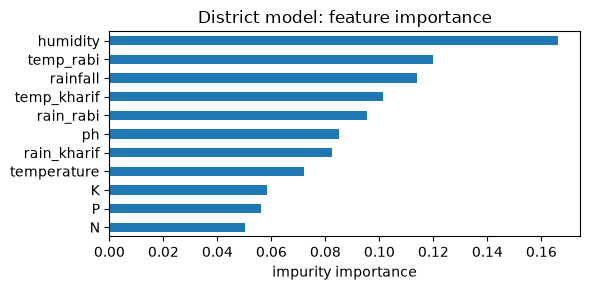

In [9]:
imp = pd.Series(forest.feature_importances_, index=APP_FEATURES).sort_values()
ax = imp.plot.barh(figsize=(6, 3)); ax.set_xlabel('impurity importance'); ax.set_title('District model: feature importance')
plt.tight_layout(); plt.savefig(FIGS / 'district_model_importance.png', dpi=150)
imp.round(3)

## 4. Findings

1. **Real data fixes the transfer problem.** The Kaggle model put the main crop in its list for 8% of districts
   (notebook 08, Kaggle crops only). With 27 crops the district model reaches 80%, leave-one-state-out.
2. **The 12 added crops matter.** Wheat is the main crop in 22% of districts and soybean, sugarcane and groundnut in
   another 9%; without them "main crop" was rice for 69% of districts and the task was nearly trivial.
3. **Against "the 3 most common crops"** the app model puts the main crop *first* far more often (62.5% vs 50.1%) and
   in the list a little more often (80.5% vs 76.3%, +4.3 pts, 95% CI 0.7–7.8). Gains are in mixed states
   (Maharashtra 47% vs 26%, Gujarat 56% vs 41%); rice states are easy for every method.
4. **Season weather and humidity help; soil alone does not** (RF soil only: 46% first, below popularity). Weather
   carries most of the signal at district scale.
5. **Logistic regression is 2.2 pts better at getting the main crop into the list** (CI 0.0–4.5) and level on the rest
   (first 61.4% vs 62.5%). RF stays for the app because SHAP on the forest gives explanations that add up to the
   suitability shown; this is a known trade-off for the paper.
6. Random district folds would report 85.3% instead of 77.7% for the same model: geography leaks between neighbours.
   The example districts were in training, so their near-perfect match is no evidence.
7. Limits: suitability is revealed preference (what similar districts grow), trained on district averages while the
   app gets one farm's card; fruit areas can be old (series ending before 2010-11 are dropped, so grapes fell below 20 districts); onion and potato prices are hard to forecast (MAPE 62%, 41%).

Re-run Nov 4 after two data fixes in `data.district_yield()`: DES rice converted from milled rice to paddy, and series last reported before 2010-11 dropped. Results moved by under 2 points; grapes left the crop list (28 → 27). Re-run again the same day with the Soil Health Card's own class limits (pH 6.5/8.2, P 28/56, K 140/280 kg/ha; `data.SHC_LEVELS`), so soil is on the scale printed on the card: results moved by under 1 point.